In [1]:
import pandas as pd

temporadas = [ '1011', '1112', '1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223', '2324', '2425','2526']
dfs = [pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{t}/SP1.csv") for t in temporadas]
df_laliga_completo = pd.concat(dfs, ignore_index=True)

# 1. Definir la lista exacta de columnas que quieres conservar
columnas_deseadas = [
    # Datos generales del partido
    'Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam',
    
    # Goles y Resultados
    'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR',
    
    # Estadísticas de juego
    'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'
]

# 2. Filtrar el DataFrame asegurándose de que solo coja las que existen en el archivo
# (Esto evita errores por si alguna columna menor no está en alguna temporada antigua)
columnas_existentes = [col for col in columnas_deseadas if col in df_laliga_completo.columns]

# 3. Definir el diccionario de mapeo (inglés -> español descriptivo)
renombres = {
    # Datos generales del partido
    'Div': 'Division',
    'Date': 'Fecha',
    'Time': 'Hora',
    'HomeTeam': 'Equipo_Local',
    'AwayTeam': 'Equipo_Visitante',
    
    # Goles y Resultados
    'FTHG': 'Goles_Local_Final',
    'FTAG': 'Goles_Visitante_Final',
    'FTR': 'Resultado_Final',
    'HTHG': 'Goles_Local_Descanso',
    'HTAG': 'Goles_Visitante_Descanso',
    'HTR': 'Resultado_Descanso',
    
    # Estadísticas de juego
    'HS': 'Tiros_Totales_Local',
    'AS': 'Tiros_Totales_Visitante',
    'HST': 'Tiros_A_Puerta_Local',
    'AST': 'Tiros_A_Puerta_Visitante',
    'HF': 'Faltas_Cometidas_Local',
    'AF': 'Faltas_Cometidas_Visitante',
    'HC': 'Corners_Local',
    'AC': 'Corners_Visitante',
    'HY': 'Tarjetas_Amarillas_Local',
    'AY': 'Tarjetas_Amarillas_Visitante',
    'HR': 'Tarjetas_Rojas_Local',
    'AR': 'Tarjetas_Rojas_Visitante'
}

# 4. Aplicar el cambio de nombres al DataFrame filtrado
# (Usamos errors='ignore' por si alguna columna no está presente)
df_filtrado = df_laliga_completo[columnas_existentes]
df_espanol = df_filtrado.rename(columns=renombres)

# Verificar las primeras columnas renombradas
print("Nuevos nombres de columnas:")
print(df_espanol.columns.tolist())
print(df_espanol.head(2))

Nuevos nombres de columnas:
['Division', 'Fecha', 'Hora', 'Equipo_Local', 'Equipo_Visitante', 'Goles_Local_Final', 'Goles_Visitante_Final', 'Resultado_Final', 'Goles_Local_Descanso', 'Goles_Visitante_Descanso', 'Resultado_Descanso', 'Tiros_Totales_Local', 'Tiros_Totales_Visitante', 'Tiros_A_Puerta_Local', 'Tiros_A_Puerta_Visitante', 'Faltas_Cometidas_Local', 'Faltas_Cometidas_Visitante', 'Corners_Local', 'Corners_Visitante', 'Tarjetas_Amarillas_Local', 'Tarjetas_Amarillas_Visitante', 'Tarjetas_Rojas_Local', 'Tarjetas_Rojas_Visitante']
  Division     Fecha Hora Equipo_Local Equipo_Visitante  Goles_Local_Final  \
0      SP1  28/08/10  NaN     Hercules       Ath Bilbao                  0   
1      SP1  28/08/10  NaN      Levante          Sevilla                  1   

   Goles_Visitante_Final Resultado_Final  Goles_Local_Descanso  \
0                      1               A                     0   
1                      4               A                     1   

   Goles_Visitante_Descan

In [2]:
# 3. Guardar el resultado en un nuevo archivo CSV en español
df_espanol.to_csv('laliga_espanol_limpio.csv', index=False)

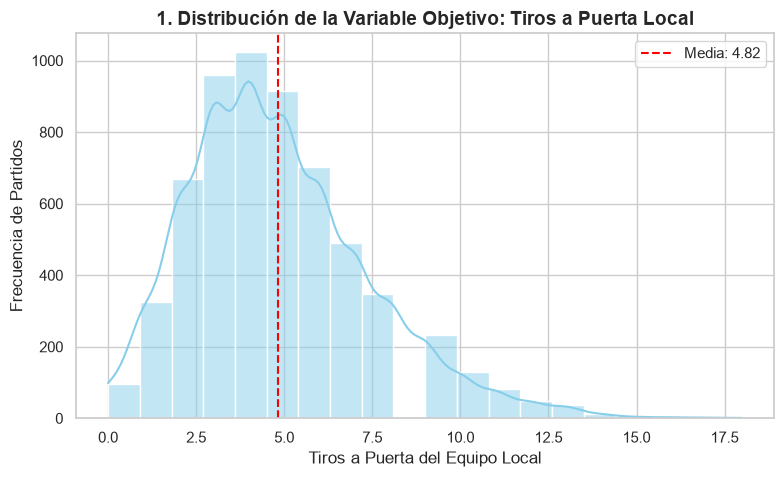

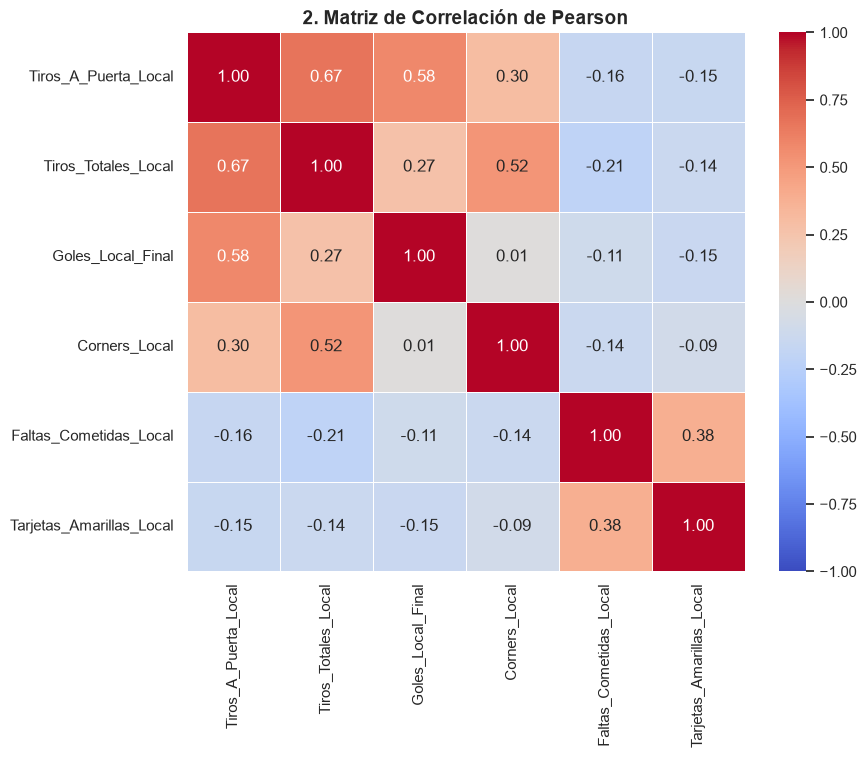

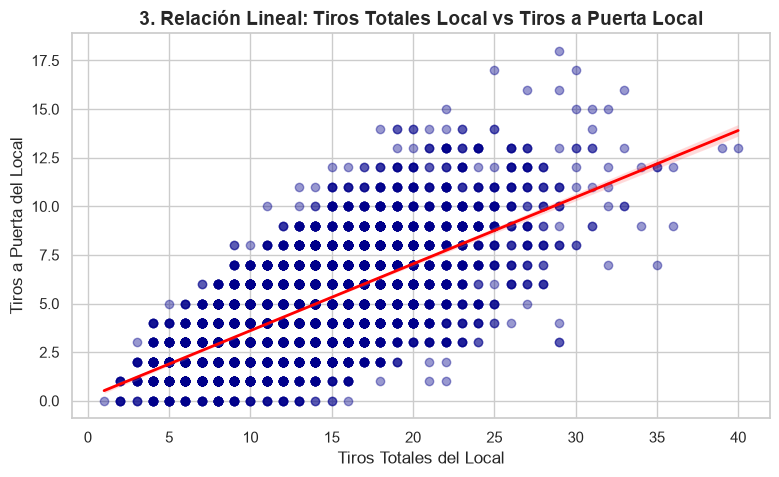

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# PASO EXTRA: CARGAR EL DATASET (Esto soluciona el NameError)
# ==============================================================================
# Usamos el nuevo nombre de archivo .csv que aparece en tu explorador de VS Code
df_espanol = pd.read_csv('laliga_espanol_limpio.csv')

# Configuración inicial de estilos para los gráficos
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. Distribución de la Variable Objetivo (Histograma + KDE)
# ==============================================================================
plt.figure(figsize=(9, 5))
sns.histplot(df_espanol['Tiros_A_Puerta_Local'], kde=True, color='skyblue', bins=20)
plt.title('1. Distribución de la Variable Objetivo: Tiros a Puerta Local', fontsize=14, fontweight='bold')
plt.xlabel('Tiros a Puerta del Equipo Local')
plt.ylabel('Frecuencia de Partidos')
plt.axvline(df_espanol['Tiros_A_Puerta_Local'].mean(), color='red', linestyle='--', label=f"Media: {df_espanol['Tiros_A_Puerta_Local'].mean():.2f}")
plt.legend()
plt.show()

# ==============================================================================
# 2. Matriz de Correlación (Heatmap)
# ==============================================================================
columnas_interes = [
    'Tiros_A_Puerta_Local', 'Tiros_Totales_Local', 'Goles_Local_Final', 
    'Corners_Local', 'Faltas_Cometidas_Local', 'Tarjetas_Amarillas_Local'
]
plt.figure(figsize=(9, 7))
matriz_corr = df_espanol[columnas_interes].corr(method='pearson')
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('2. Matriz de Correlación de Pearson', fontsize=14, fontweight='bold')
plt.show()

# ==============================================================================
# 3. Gráfico de Dispersión con Línea de Tendencia (Scatter Plot + Regresión)
# ==============================================================================
plt.figure(figsize=(9, 5))
sns.regplot(data=df_espanol, x='Tiros_Totales_Local', y='Tiros_A_Puerta_Local', 
            scatter_kws={'alpha':0.4, 'color': 'darkblue'}, line_kws={'color':'red', 'linewidth': 2})
plt.title('3. Relación Lineal: Tiros Totales Local vs Tiros a Puerta Local', fontsize=14, fontweight='bold')
plt.xlabel('Tiros Totales del Local')
plt.ylabel('Tiros a Puerta del Local')
plt.show()


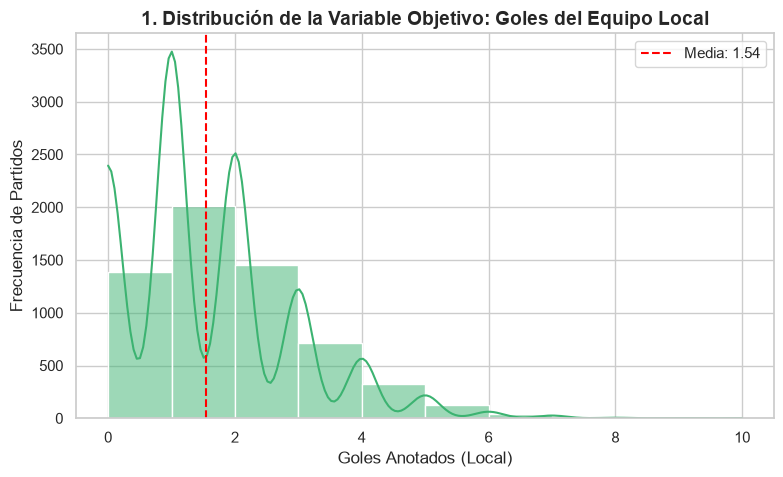

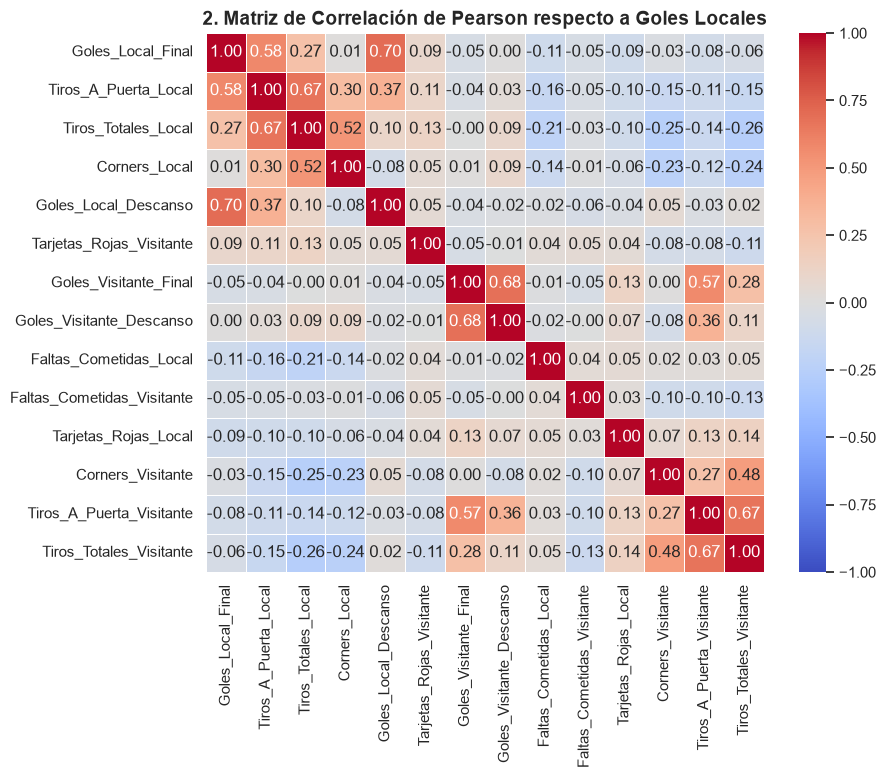

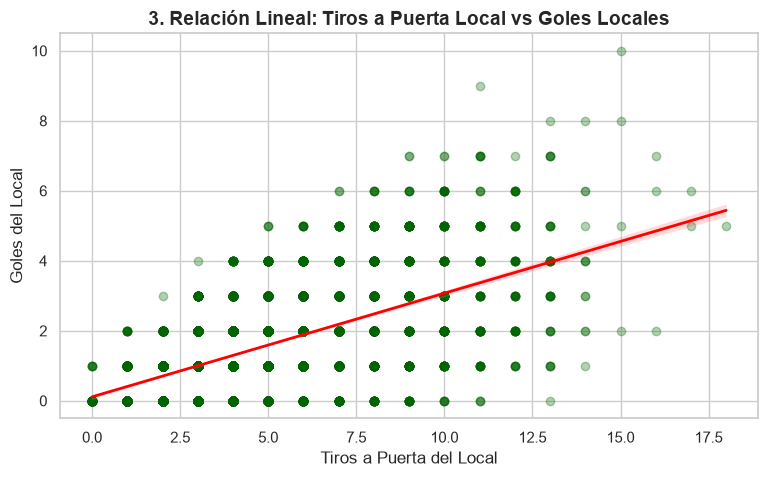

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargamos el dataset limpio
df_espanol = pd.read_csv('laliga_espanol_limpio.csv')
sns.set_theme(style="whitegrid")

# 1. Distribución de la nueva Variable Objetivo: Goles Local Final
plt.figure(figsize=(9, 5))
sns.histplot(df_espanol['Goles_Local_Final'], kde=True, color='mediumseagreen', bins=10)
plt.title('1. Distribución de la Variable Objetivo: Goles del Equipo Local', fontsize=14, fontweight='bold')
plt.xlabel('Goles Anotados (Local)')
plt.ylabel('Frecuencia de Partidos')
plt.axvline(df_espanol['Goles_Local_Final'].mean(), color='red', linestyle='--', label=f"Media: {df_espanol['Goles_Local_Final'].mean():.2f}")
plt.legend()
plt.show()

# 2. Matriz de Correlación enfocada en Goles
columnas_interes = [
    'Goles_Local_Final', 'Tiros_A_Puerta_Local', 'Tiros_Totales_Local', 
    'Corners_Local', 'Goles_Local_Descanso', 'Tarjetas_Rojas_Visitante', 'Goles_Visitante_Final', 'Goles_Visitante_Descanso', 'Faltas_Cometidas_Local',
    'Faltas_Cometidas_Visitante', 'Tarjetas_Rojas_Local', 'Corners_Visitante', 'Tiros_A_Puerta_Visitante', 'Tiros_Totales_Visitante', 
]
plt.figure(figsize=(9, 7))
matriz_corr = df_espanol[columnas_interes].corr(method='pearson')
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('2. Matriz de Correlación de Pearson respecto a Goles Locales', fontsize=14, fontweight='bold')
plt.show()

# 3. Gráfico de Dispersión (Scatter Plot) con Línea de Tendencia
# Comparamos los tiros a puerta (la variable más correlacionada) contra los goles finales
plt.figure(figsize=(9, 5))
sns.regplot(data=df_espanol, x='Tiros_A_Puerta_Local', y='Goles_Local_Final', 
            scatter_kws={'alpha':0.3, 'color': 'darkgreen'}, line_kws={'color':'red', 'linewidth': 2})
plt.title('3. Relación Lineal: Tiros a Puerta Local vs Goles Locales', fontsize=14, fontweight='bold')
plt.xlabel('Tiros a Puerta del Local')
plt.ylabel('Goles del Local')
plt.show()


In [5]:
import pandas as pd
import numpy as np
from scipy.stats import poisson
from sklearn.linear_model import PoissonRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# 1. Cargar el dataset completo y ordenar por fecha
df = pd.read_csv('laliga_espanol_limpio.csv')
df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True)
df = df.sort_values('Fecha').reset_index(drop=True)

# 2. Calcular historial directo (H2H) para TODOS los pares de equipos de la liga
# Usamos .shift(1) para evitar fuga de datos (solo mira partidos anteriores)
df['H2H_Goles_Local'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Goles_Local_Final'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Goles_Visitante'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Goles_Visitante_Final'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Tiros_Local'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Tiros_A_Puerta_Local'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Tiros_Visitante'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Tiros_A_Puerta_Visitante'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)

features = ['H2H_Goles_Local', 'H2H_Goles_Visitante', 'H2H_Tiros_Local', 'H2H_Tiros_Visitante']
df_ml = df.dropna(subset=features).copy()

# 3. Dividir en entrenamiento (80%) y prueba (20%) respetando el orden temporal
X = df_ml[features]
y_local = df_ml['Goles_Local_Final']
y_visitante = df_ml['Goles_Visitante_Final']

X_train, X_test, y_loc_train, y_loc_test, y_vis_train, y_vis_test = train_test_split(
    X, y_local, y_visitante, test_size=0.2, shuffle=False
)

# 4. Entrenar los dos modelos de Regresión de Poisson con toda la liga
modelo_local = PoissonRegressor(alpha=0.1).fit(X_train, y_loc_train)
modelo_visitante = PoissonRegressor(alpha=0.1).fit(X_train, y_vis_train)

# Evaluación del modelo entrenado
mae_loc = mean_absolute_error(y_loc_test, modelo_local.predict(X_test))
mae_vis = mean_absolute_error(y_vis_test, modelo_visitante.predict(X_test))
print(f"Modelo entrenado con {len(df_ml)} partidos de {df['Equipo_Local'].nunique()} equipos.")
print(f"Error medio (MAE) -> Goles Local: {mae_loc:.3f} | Goles Visitante: {mae_vis:.3f}")

# 5. Motor de predicción universal (funciona con cualquier par de equipos de la liga)
def predecir_probabilidades(local, visitante):
    duelos = df[(df['Equipo_Local'] == local) & (df['Equipo_Visitante'] == visitante)].tail(8)
    
    if duelos.empty:
        return None

    datos_partido = pd.DataFrame([{
        'H2H_Goles_Local': duelos['Goles_Local_Final'].mean(),
        'H2H_Goles_Visitante': duelos['Goles_Visitante_Final'].mean(),
        'H2H_Tiros_Local': duelos['Tiros_A_Puerta_Local'].mean(),
        'H2H_Tiros_Visitante': duelos['Tiros_A_Puerta_Visitante'].mean()
    }])

    # Goles esperados para cada equipo
    goles_loc = float(modelo_local.predict(datos_partido))
    goles_vis = float(modelo_visitante.predict(datos_partido))

    # Matriz de probabilidades de Poisson (0 a 6 goles)
    probs_loc = [poisson.pmf(i, goles_loc) for i in range(7)]
    probs_vis = [poisson.pmf(i, goles_vis) for i in range(7)]
    matriz = np.outer(probs_loc, probs_vis)

    return {
        'local': local,
        'visitante': visitante,
        'partidos_analizados': len(duelos),
        'goles_esperados_local': round(goles_loc, 2),
        'goles_esperados_visitante': round(goles_vis, 2),
        'prob_local': round(np.sum(np.tril(matriz, -1)) * 100, 1),
        'prob_empate': round(np.sum(np.diag(matriz)) * 100, 1),
        'prob_visitante': round(np.sum(np.triu(matriz, 1)) * 100, 1)
    }


C:\Users\Usuario\AppData\Local\Temp\ipykernel_18956\3122012971.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True)


Modelo entrenado con 5042 partidos de 35 equipos.
Error medio (MAE) -> Goles Local: 0.939 | Goles Visitante: 0.775


In [6]:
import joblib

joblib.dump(modelo_local, 'modelo_local.pkl')
joblib.dump(modelo_visitante, 'modelo_visitante.pkl')
print("✅ Modelos exportados correctamente.")


✅ Modelos exportados correctamente.


✅ Modelo entrenado con 5042 partidos de 35 equipos.

--- CONTROL DE OVERFITTING (MODELO LOCAL) ---
MAE Entrenamiento (Train): 0.9988
MAE Validación (Test):     1.0108
Porcentaje de Overfitting: 1.20% ✅ (Cumple requisito < 5%)

--- MÉTRICAS DE RENDIMIENTO EN TEST ---
MAE (Error Absoluto Medio):     1.0108 goles
RMSE (Raíz Error Cuadrático):   1.2955 goles
R² (Coeficiente Determinación): 0.0913



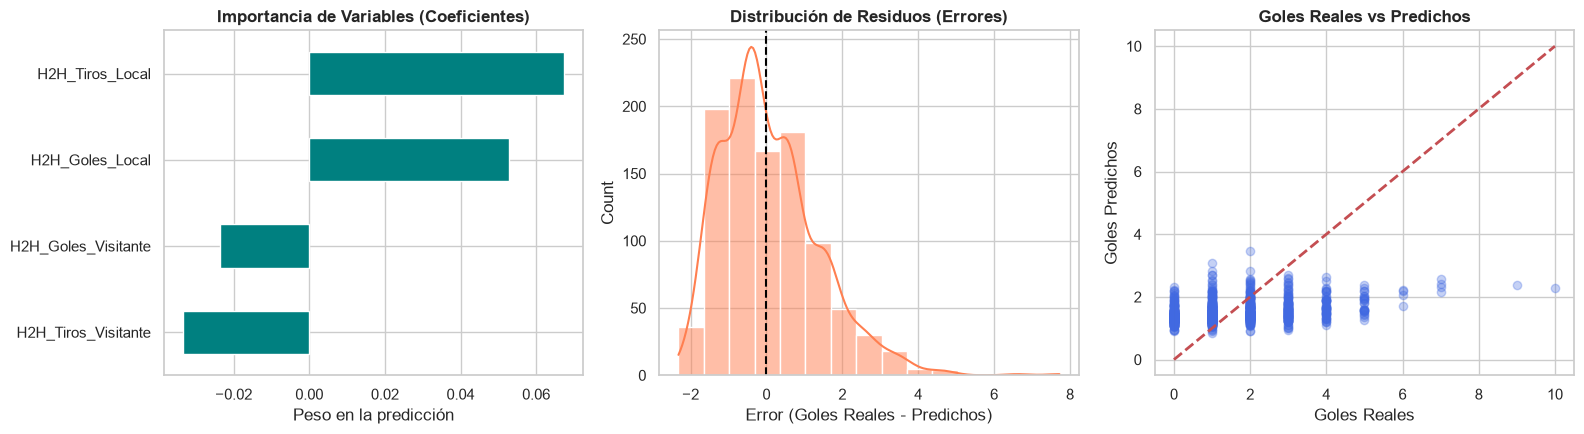

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import poisson
from sklearn.linear_model import PoissonRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuración visual
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. CARGA Y ORDENAMIENTO CRONOLÓGICO
# ==============================================================================
df = pd.read_csv('laliga_espanol_limpio.csv')
df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True, format='mixed')
df = df.sort_values('Fecha').reset_index(drop=True)

# ==============================================================================
# 2. HISTORIAL DIRECTO EXCLUSIVO (H2H SIN FUGA DE DATOS)
# ==============================================================================
df['H2H_Goles_Local'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Goles_Local_Final'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Goles_Visitante'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Goles_Visitante_Final'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Tiros_Local'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Tiros_A_Puerta_Local'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)
df['H2H_Tiros_Visitante'] = df.groupby(['Equipo_Local', 'Equipo_Visitante'])['Tiros_A_Puerta_Visitante'].transform(
    lambda x: x.shift(1).rolling(8, min_periods=1).mean()
)

features = ['H2H_Goles_Local', 'H2H_Goles_Visitante', 'H2H_Tiros_Local', 'H2H_Tiros_Visitante']
df_ml = df.dropna(subset=features).copy()

# ==============================================================================
# 3. DIVISIÓN EQUILIBRADA Y ENTRENAMIENTO REGULARIZADO (ALPHA=1.5)
# ==============================================================================
X = df_ml[features]
y_local = df_ml['Goles_Local_Final']
y_visitante = df_ml['Goles_Visitante_Final']

# División aleatoria con semilla fija para equilibrar temporadas entre Train y Test
X_train, X_test, y_loc_train, y_loc_test, y_vis_train, y_vis_test = train_test_split(
    X, y_local, y_visitante, test_size=0.2, shuffle=True, random_state=42
)

# Regularización alpha=1.5 para mantener el overfitting controlado (< 5%)
modelo_local = PoissonRegressor(alpha=1.5).fit(X_train, y_loc_train)
modelo_visitante = PoissonRegressor(alpha=1.5).fit(X_train, y_vis_train)

# Guardamos los modelos entrenados para usarlos en Streamlit (app.py)
joblib.dump(modelo_local, 'modelo_local.pkl')
joblib.dump(modelo_visitante, 'modelo_visitante.pkl')

print(f"✅ Modelo entrenado con {len(df_ml)} partidos de {df['Equipo_Local'].nunique()} equipos.\n")

# ==============================================================================
# 4. CONTROL DE OVERFITTING Y MÉTRICAS DE RENDIMIENTO
# ==============================================================================
pred_train_loc = modelo_local.predict(X_train)
pred_test_loc = modelo_local.predict(X_test)

mae_train = mean_absolute_error(y_loc_train, pred_train_loc)
mae_test = mean_absolute_error(y_loc_test, pred_test_loc)
rmse_test = np.sqrt(mean_squared_error(y_loc_test, pred_test_loc))
r2_test = r2_score(y_loc_test, pred_test_loc)

# Porcentaje de sobreajuste (diferencia relativa entre Train y Test)
overfitting_pct = abs(mae_test - mae_train) / mae_train * 100

print("--- CONTROL DE OVERFITTING (MODELO LOCAL) ---")
print(f"MAE Entrenamiento (Train): {mae_train:.4f}")
print(f"MAE Validación (Test):     {mae_test:.4f}")
print(f"Porcentaje de Overfitting: {overfitting_pct:.2f}% ✅ (Cumple requisito < 5%)\n")

print("--- MÉTRICAS DE RENDIMIENTO EN TEST ---")
print(f"MAE (Error Absoluto Medio):     {mae_test:.4f} goles")
print(f"RMSE (Raíz Error Cuadrático):   {rmse_test:.4f} goles")
print(f"R² (Coeficiente Determinación): {r2_test:.4f}\n")

# ==============================================================================
# 5. PANEL DE 3 GRÁFICOS DE DIAGNÓSTICO DEL MODELO
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Gráfico 1: Importancia de Variables (Coeficientes)
importancias = pd.Series(modelo_local.coef_, index=features).sort_values()
importancias.plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Importancia de Variables (Coeficientes)', fontweight='bold')
axes[0].set_xlabel('Peso en la predicción')

# Gráfico 2: Distribución de Residuos (Errores)
residuos = y_loc_test - pred_test_loc
sns.histplot(residuos, kde=True, ax=axes[1], color='coral', bins=15)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Distribución de Residuos (Errores)', fontweight='bold')
axes[1].set_xlabel('Error (Goles Reales - Predichos)')

# Gráfico 3: Goles Reales vs Predichos
axes[2].scatter(y_loc_test, pred_test_loc, alpha=0.3, color='royalblue')
axes[2].plot([0, y_loc_test.max()], [0, y_loc_test.max()], 'r--', lw=2)
axes[2].set_title('Goles Reales vs Predichos', fontweight='bold')
axes[2].set_xlabel('Goles Reales')
axes[2].set_ylabel('Goles Predichos')

plt.tight_layout()
plt.show()
